In [1]:
import numpy as np
import scipy.linalg as sla
import numpy.linalg as la
import random
import matplotlib.pyplot as plt
%matplotlib inline

# Obtaining eigenvalues and eigenvectors numerically

We want to prepare a matrix with deliberately chosen eigenvalues. Let's use diagonalization to write the matrix $\mathbf{A}$:

$$ \mathbf{A} = \mathbf{U D U}^{-1} $$

where we set ${\bf D}$ to be a known matrix with the pre-defined eigenvalues:

```python
D = np.diag([lambda1, lambda2, ..., lambdan])
```

We need to generate a matrix $\mathbf{U}$ that has an inverse. Orthogonal matrices are a great option here, since $\mathbf{U}^{-1} = \mathbf{U}^T$. We use QR decomposition to get an orthogonal matrix (you don't need to understand this method).

In [2]:
n = 4
X = np.random.rand(n,n)
U,_ = sla.qr(X)

D = np.diag([6,2,4,7])

In [3]:
print(U)

[[-0.67029557  0.63787996  0.36335512  0.10856363]
 [-0.37355905 -0.62995708  0.54050651 -0.4140778 ]
 [-0.53643047 -0.07213359 -0.74842965 -0.38326512]
 [-0.35128312 -0.43710408 -0.12521511  0.81845059]]


Now we can use diagonalization to write $\mathbf{A}$

In [4]:
A = U@D@U.T

And we can check that the eigenvalues are indeed what we expected:

In [5]:
eigl, eigv = la.eig(A)
print(eigl)
print(eigv)

[2.+0.j 4.+0.j 6.+0.j 7.+0.j]
[[-0.63787996+0.j  0.36335512+0.j -0.67029557+0.j  0.10856363+0.j]
 [ 0.62995708+0.j  0.54050651+0.j -0.37355905+0.j -0.4140778 +0.j]
 [ 0.07213359+0.j -0.74842965+0.j -0.53643047+0.j -0.38326512+0.j]
 [ 0.43710408+0.j -0.12521511+0.j -0.35128312+0.j  0.81845059+0.j]]


We want to find the eigenvector corresponding to the largest eigenvalue in magnitude. For that, we can use `np.argsort`, which returns the indices that sort the array in ascending order. Hence, we are interested in the last entry.

In [6]:
eig_index_sort = np.argsort(abs(eigl))
print(eig_index_sort)
eigpos = eig_index_sort[-1]
print(eigpos)

[0 1 2 3]
3


Recall that eigenvectors are stored as columns! Hence this would be the eigenvector corresponding to the largest (in magnitude) eigenvalue.

In [7]:
eigv[:,eigpos]

array([ 0.10856363+0.j, -0.4140778 +0.j, -0.38326512+0.j,  0.81845059+0.j])

# Power Iteration

Let's pick an initial vector:

In [8]:
x0 = np.random.randn(n)
x0

array([-0.89322185,  0.47340497,  0.80336824, -1.68886053])

And we perform matrix-vector multiplications:

In [9]:
x = x0

In [10]:
x = A@x
print(x)

[ -4.7624428    3.68416203   4.83984544 -12.19932774]


Power iteration should converge to a multiple of the eigenvector ${\bf u}_1$ corresponding to largest eigenvalue (in magnitude).

$$ {\bf x}_k = (\lambda_1)^k \left[ \alpha_1 {\bf u}_1 + \alpha_2 \left(\frac{\lambda_2}{\lambda_1}\right)^k{\bf u}_2 + ...  \right] $$

Let's implememt power iteration. We simply perform multiple matrix vector multiplications using a for loop:

In [11]:
x = x0
for i in range(40):
    x = A @ x
    print(x)
    
print('Exact eigenvalue = ',eigv[:,eigpos])

[ -4.7624428    3.68416203   4.83984544 -12.19932774]
[-27.79101732  28.8895565   31.50616931 -85.67347664]
[-170.04884229  219.61266198  215.08358983 -596.72325668]
[-1068.98488331  1627.27495691  1506.85178552 -4147.04040242]
[ -6837.88235346  11854.60712122  10689.49263229 -28813.97435609]
[ -44289.3056872    85421.55749824   76207.01655785 -200291.53248259]
[ -289670.07426449   611139.91118613   543849.40712875 -1393197.76860792]
[-1909807.48010365  4351174.70239247  3877797.79320253 -9697810.74133193]
[-12678036.96999403  30873337.19027587  27603462.32851427
 -67551379.88364875]
[-8.46686847e+07  2.18507210e+08  1.96112498e+08 -4.70836894e+08]
[-5.68478595e+08  1.54352501e+09  1.39065690e+09 -3.28363053e+09]
[-3.83518751e+09  1.08869657e+10  9.84397386e+09 -2.29116845e+10]
[-2.59855339e+10  7.66962718e+10  6.95727062e+10 -1.59937968e+11]
[-1.76750845e+11  5.39774040e+11  4.91032821e+11 -1.11689705e+12]
[-1.20643565e+12  3.79571935e+12  3.46151118e+12 -7.80224385e+12]
[-8.26039634e

* What's the problem with this method?
* Does anything useful come of this?
* How do we fix it?

We can get the corresponding eigenvalue

In [12]:
np.dot(x,A@x)/np.dot(x,x)

np.float64(6.9999996174737875)

# Normalized power iteration

Back to the beginning: Reset to the initial vector and normalize

In [13]:
x = x0/la.norm(x0)

Implement normalized power iteration. We will start with 10 iterations, and see what happens...

In [14]:
x = x0/la.norm(x0)

for i in range(20):
    x = A @ x
    nrm = la.norm(x)
    x = x/nrm
    print(x)

print('exact = ' ,eigv[:,eigpos])

print('eig_approx = ', (x.T@A@x)/(x.T@x))

[-0.32981854  0.25514321  0.33517899 -0.84485308]
[-0.27875426  0.28977302  0.31601862 -0.85933689]
[-0.2455759   0.31715345  0.3106128  -0.86175742]
[-0.22165282  0.33741364  0.31244403 -0.85988418]
[-0.20325303  0.35237295  0.31774044 -0.85648264]
[-0.18853753  0.36363563  0.32440976 -0.85263183]
[-0.17647813  0.3723299   0.33133394 -0.84878957]
[-0.16643878  0.37920273  0.33794817 -0.84515943]
[-0.15799437  0.38474516  0.3439958  -0.84182886]
[-0.15084295  0.38928528  0.34938759 -0.83882757]
[-0.14475937  0.39304858  0.35412171 -0.8361551 ]
[-0.13956902  0.39619526  0.35823901 -0.83379531]
[-0.13513239  0.39884309  0.36179846 -0.8317243 ]
[-0.13133546  0.40108137  0.364864   -0.82991505]
[-0.12808353  0.40297975  0.36749791 -0.82834004]
[-0.12529709  0.40459375  0.36975762 -0.8269727 ]
[-0.12290884  0.40596839  0.37169458 -0.82578824]
[-0.12086155  0.40714073  0.37335404 -0.82476401]
[-0.1191064   0.40814154  0.37477536 -0.82387959]
[-0.11760166  0.40899655  0.37599257 -0.8231168 ]


### What if the starting guess does not have any component of ${\bf u}_1$, i.e., if $\alpha_1 = 0$? 

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$

In theory (or infinite precision calculations), if $\alpha_1=0$, power iteration will converge to a vector that is a multiple of the eigenvector ${\bf u}_2$. 


In practice, it is unlikely that a random vector ${\bf x}_0$ will not have any component of ${\bf u}_1$. In the chances that happens, finite operations during the iterative process will usually introduce such component.

### Creating a matrix where the dominant eigenvalue is negative

In [15]:
U

array([[-0.67029557,  0.63787996,  0.36335512,  0.10856363],
       [-0.37355905, -0.62995708,  0.54050651, -0.4140778 ],
       [-0.53643047, -0.07213359, -0.74842965, -0.38326512],
       [-0.35128312, -0.43710408, -0.12521511,  0.81845059]])

In [16]:
n = 4
    
D = np.diag([-5,2,4,3])

A = U@D@U.T

eigl, eigv = la.eig(A)

eig_index_sort = np.argsort(abs(eigl))
eigpos = eig_index_sort[-1]

print(eigl)
print(eigv[:,eigpos])

[-5.+0.j  4.+0.j  2.+0.j  3.+0.j]
[0.67029557+0.j 0.37355905+0.j 0.53643047+0.j 0.35128312+0.j]


In [17]:
x = x0/la.norm(x0)

for i in range(40):
    x = A @ x
    nrm = la.norm(x)
    x = x/nrm
    print(x)

print('exact = ' ,eigv[:,eigpos])

print('eig_approx = ', np.dot(x,A@x)/np.dot(x,x))

print(D)

[ 0.05897474  0.40655612  0.76182072 -0.50086255]
[-0.61421778 -0.0643072   0.18793939 -0.76372763]
[ 0.33104552  0.36278943  0.85886777 -0.14539205]
[-0.73768702 -0.31606729 -0.11119766 -0.58613514]
[0.51240759 0.32459671 0.77908069 0.1584573 ]
[-0.73859365 -0.40491977 -0.3113372  -0.43998699]
[0.58929319 0.31857972 0.68382872 0.28916911]
[-0.71711752 -0.41671564 -0.41180215 -0.37750435]
[0.62443668 0.32883418 0.62456405 0.33446474]
[-0.7005343  -0.40904934 -0.46375255 -0.35617959]
[0.64294706 0.34142918 0.5902214  0.34883218]
[-0.68967614 -0.39905487 -0.4925056  -0.35005751]
[0.65352172 0.35174576 0.56988473 0.35272606]
[-0.68271736 -0.39087871 -0.50927332 -0.34892911]
[0.65983661 0.35915813 0.55749501 0.35329931]
[-0.67826035 -0.38500807 -0.51940369 -0.34921552]
[0.66370822 0.36418828 0.54979099 0.35297049]
[-0.67540244 -0.38101963 -0.5256648  -0.34976008]
[0.66612092 0.36750804 0.54493967 0.35250746]
[-0.67356913 -0.37838269 -0.5295894  -0.35023741]
[0.66763987 0.36966778 0.5418622

What is happening here? Note that the scalar that multiplies the eigenvector ${\bf u}_1$ in 

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$

is $(\lambda_1)^k$, and hence if the eigenvalue  $\lambda_1$ is negative, the solution of power iteration will converge to the eigenvector, but with alternating signs, i.e., ${\bf u}_1$ and $-{\bf u}_1$.

### When dealing with dominant eigenvalues of multiplicity greater than 1: $|\lambda_1| = |\lambda_2| $ and $ \lambda_1, \lambda_2 > 0 $


In [18]:
n = 4

D = np.diag([5,5,2,1])

A = U@D@U.T

eigl, eigv = la.eig(A)

print(eigl)
print(eigv[:,2])
print(eigv[:,3])

[2.+0.j 1.+0.j 5.+0.j 5.+0.j]
[0.56944321+0.j 0.46195051+0.j 0.54120861+0.j 0.41161802+0.j]
[ 0.72932943+0.j -0.56832562+0.j  0.00735858+0.j -0.38082859+0.j]


In [19]:
x = x0/la.norm(x0)

for i in range(40):
    x = A @ x
    nrm = la.norm(x)
    x = x/nrm
    print(x)

print('u1_exact = ' ,eigv[:,2])
print('u2_exact = ' ,eigv[:,3])

print('eig_approx = ', np.dot(x,A@x)/np.dot(x,x))

print(D)

[-0.82440315 -0.04626706 -0.0140313  -0.56393432]
[-0.87728811 -0.1713615  -0.34432342 -0.28712749]
[-0.85223523 -0.17779011 -0.44228768 -0.21556298]
[-0.84065796 -0.1710762  -0.47224867 -0.20250512]
[-0.83617892 -0.16661472 -0.48250175 -0.20059013]
[-0.8344421  -0.16448028 -0.48626665 -0.20049281]
[-0.83376023 -0.16355696 -0.48770628 -0.2005881 ]
[-0.83349028 -0.16317377 -0.48826898 -0.2006531 ]
[-0.8333829  -0.16301773 -0.48849146 -0.20068449]
[-0.83334007 -0.16295476 -0.48857992 -0.20069813]
[-0.83332296 -0.16292946 -0.48861521 -0.2007038 ]
[-0.83331612 -0.16291932 -0.4886293  -0.20070611]
[-0.83331339 -0.16291526 -0.48863494 -0.20070704]
[-0.83331229 -0.16291363 -0.48863719 -0.20070742]
[-0.83331186 -0.16291298 -0.48863809 -0.20070757]
[-0.83331168 -0.16291272 -0.48863845 -0.20070763]
[-0.83331161 -0.16291262 -0.48863859 -0.20070765]
[-0.83331158 -0.16291258 -0.48863865 -0.20070766]
[-0.83331157 -0.16291256 -0.48863867 -0.20070767]
[-0.83331157 -0.16291255 -0.48863868 -0.20070767]


In general, power method converges to:

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$

However if $|\lambda_1| = |\lambda_2| $ and $ \lambda_1, \lambda_2 > 0 $, we get:

$$ {\bf x}_k = (\lambda_1)^k \left( \alpha_1 {\bf u}_1 + \alpha_2 {\bf u}_2 \right) + \left[ ...  \right] $$

and hence the solution of power iteration will converge to a multiple of the linear combination of the eigenvectors ${\bf u}_1$ and ${\bf u}_2$.

### When dealing with dominant eigenvalues of multiplicity greater than 1: $|\lambda_1| = |\lambda_2| $ and $ \lambda_1, \lambda_2 < 0 $


In [20]:
n = 4

D = np.diag([-5,-5,2,1])

A = U@D@U.T

eigl, eigv = la.eig(A)

print(eigl)
print(eigv[:,2])
print(eigv[:,3])

[ 2.+0.j  1.+0.j -5.+0.j -5.+0.j]
[-0.92530373+0.j  0.16366736+0.j -0.33886646+0.j  0.04685641+0.j]
[0.53395366+0.j 0.4885716 +0.j 0.54023925+0.j 0.42933999+0.j]


In [21]:
x = x0/la.norm(x0)

for i in range(40):
    x = A @ x
    nrm = la.norm(x)
    x = x/nrm
    print(x)

print('u1_exact = ' ,eigv[:,2])
print('u2_exact = ' ,eigv[:,3])

print('eig_approx = ', np.dot(x,A@x)/np.dot(x,x))

print(D)

[ 0.53316863  0.21913845  0.78202401 -0.2369557 ]
[-0.87728811 -0.1713615  -0.34432342 -0.28712749]
[0.81193084 0.14755463 0.53354893 0.18526057]
[-0.84065796 -0.1710762  -0.47224867 -0.20250512]
[0.83039454 0.15920067 0.4947465  0.20081325]
[-0.8344421  -0.16448028 -0.48626665 -0.20049281]
[0.83286165 0.1622679  0.48957037 0.20082694]
[-0.83349028 -0.16317377 -0.48826898 -0.2006531 ]
[0.8332402  0.16280737 0.4887859  0.20073084]
[-0.83334007 -0.16295476 -0.48857992 -0.20069813]
[0.83330017 0.16289564 0.48866217 0.20071154]
[-0.83331612 -0.16291932 -0.4886293  -0.20070611]
[0.83330974 0.16290984 0.48864244 0.2007083 ]
[-0.83331229 -0.16291363 -0.48863719 -0.20070742]
[0.83331127 0.16291212 0.48863929 0.20070777]
[-0.83331168 -0.16291272 -0.48863845 -0.20070763]
[0.83331152 0.16291248 0.48863879 0.20070769]
[-0.83331158 -0.16291258 -0.48863865 -0.20070766]
[0.83331156 0.16291254 0.4886387  0.20070767]
[-0.83331157 -0.16291255 -0.48863868 -0.20070767]
[0.83331156 0.16291255 0.48863869 0.

In general, power method converges to:

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$

However if $|\lambda_1| = |\lambda_2| $ and $ \lambda_1, \lambda_2 < 0 $, we get:

$$ {\bf x}_k = \pm |\lambda_1|^k \left( \alpha_1 {\bf u}_1 + \alpha_2 {\bf u}_2 \right) + \left[ ...  \right] $$

and hence the solution of power iteration will converge to a multiple of the linear combination of the eigenvectors ${\bf u}_1$ and ${\bf u}_2$, but the signs will flip at each step of the iterative method.

### When dealing with dominant eigenvalues of multiplicity greater than 1: $|\lambda_1| = |\lambda_2| $ and $ \lambda_1 , \lambda_2 $ have opposite signs


In [22]:
n = 4

D = np.diag([-5,5,2,1])

A = U@D@U.T

eigl, eigv = la.eig(A)

print(eigl)
print(eigv[:,0])
print(eigv[:,1])

[-5.+0.j  5.+0.j  2.+0.j  1.+0.j]
[0.67029557+0.j 0.37355905+0.j 0.53643047+0.j 0.35128312+0.j]
[ 0.63787996+0.j -0.62995708+0.j -0.07213359+0.j -0.43710408+0.j]


In [23]:
x = x0/la.norm(x0)

for i in range(40):
    x = A @ x
    nrm = la.norm(x)
    x = x/nrm
    print(x)

print('u1_exact = ' ,eigv[:,2])
print('u2_exact = ' ,eigv[:,3])

print('eig_approx = ', np.dot(x,A@x)/np.dot(x,x))

print(D)

[ 0.21523156  0.53312653  0.81797739 -0.0190909 ]
[-0.87728811 -0.1713615  -0.34432342 -0.28712749]
[0.42219081 0.53245384 0.57762203 0.45232799]
[-0.84065796 -0.1710762  -0.47224867 -0.20250512]
[0.4400907  0.54465668 0.53888336 0.46826702]
[-0.8344421  -0.16448028 -0.48626665 -0.20049281]
[0.44254647 0.5477351  0.53370851 0.46828848]
[-0.83349028 -0.16317377 -0.48826898 -0.2006531 ]
[0.44292474 0.54827486 0.53292408 0.46819257]
[-0.83334007 -0.16295476 -0.48857992 -0.20069813]
[0.4429847  0.54836313 0.53280034 0.46817328]
[-0.83331612 -0.16291932 -0.4886293  -0.20070611]
[0.44299428 0.54837734 0.53278062 0.46817003]
[-0.83331229 -0.16291363 -0.48863719 -0.20070742]
[0.44299581 0.54837961 0.53277746 0.46816951]
[-0.83331168 -0.16291272 -0.48863845 -0.20070763]
[0.44299605 0.54837998 0.53277696 0.46816942]
[-0.83331158 -0.16291258 -0.48863865 -0.20070766]
[0.44299609 0.54838003 0.53277688 0.46816941]
[-0.83331157 -0.16291255 -0.48863868 -0.20070767]
[0.4429961  0.54838004 0.53277687 0.

In general, power method converges to:

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$

However if $|\lambda_1| = |\lambda_2| $, $ \lambda_1, \lambda_2$ have opposite signs, we get:

$$ {\bf x}_k = \pm |\lambda_1|^k \left( \alpha_1 {\bf u}_1 \pm \alpha_2 {\bf u}_2 \right) + \left[ ...  \right] $$

and hence power iteration does not converge to one solution. Indeed, the method oscilates between two linear combination of eigenvectors, and fails to give the correct eigenvalue. 

### Summary - Pitfalls of power iteration:

- Risk of eventual overflow. Use normalized power iteration to avoid this.


- If the initial guess has $\alpha_1 = 0$, the method will converge to multiple of eigenvector ${\bf u}_2$ if infinite precision computation is used. In practice (in finite precision computations), this will not be an issue, and the method will converge to multiple of eigenvector ${\bf u}_1$.


- If the two largest eigenvalues are equal in magnitude, power iteration will converge to a vector that is a linear combination of the corresponding eigenvectors (or fail to converge). This is a real problem that cannot be discounted in practice. Other methods should be used in this case.


# Estimating the eigenvalue

We want to approximate the eigenvalue ${\bf u}_1$ using the solution of power iteration

$$ {\bf x}_k = (\lambda_1)^k  \alpha_1 {\bf u}_1 + (\lambda_1)^k  \left(\frac{\lambda_2}{\lambda_1}\right)^k \alpha_2 {\bf u}_2 + (\lambda_1)^k \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \alpha_3{\bf u}_3 +  ...  \right] $$


$ {\bf x}_k $ approaches a multiple of the eigenvector ${\bf u}_1$ as $k \rightarrow \infty$, hence

$$ {\bf x}_k  =   (\lambda_1)^k  \alpha_1 {\bf u}_1 $$

but also  

$$ {\bf x}_{k+1}  =   (\lambda_1)^{k+1}  \alpha_1 {\bf u}_1 \Longrightarrow {\bf x}_{k+1} = \lambda_1 {\bf x}_{k} $$

We can then approximate $\lambda_1$ as the ratio of corresponding entries of the vectors ${\bf x}_{k+1}$ and ${\bf x}_{k}$, i.e., 

$$ \lambda_1 \approx \frac{({\bf x}_{k+1})_j } { ({\bf x}_{k})_j }$$


# Error of Power Iteration

We define the approximated eigenvector as 

$$ {\bf u}_{approx} = \frac{{\bf x}_k } { (\lambda_1)^k  \alpha_1} $$

and hence the error becomes the part of the power iteration solution that was neglected, i.e.,

$$ {\bf e} =  {\bf u}_{approx} - {\bf u}_1 = \left(\frac{\lambda_2}{\lambda_1}\right)^k \frac{\alpha_2}{\alpha_1} {\bf u}_2 +  \left[   \left(\frac{\lambda_3}{\lambda_1}\right)^k \frac{\alpha_3}{\alpha_1}{\bf u}_3 +  ...  \right]  $$

and when $k$ is large, we can write (again, we are assuming that $|\lambda_1| > |\lambda_2|  \ge |\lambda_3|  \ge |\lambda_4| ... $ 

$${\bf e}_k \approx \left(\frac{\lambda_2}{\lambda_1}\right)^k \frac{\alpha_2}{\alpha_1} {\bf u}_2 $$

And when we take the norm of the error

$$||{\bf e}_k|| \approx \left|\frac{\lambda_2}{\lambda_1}\right|^k \left|\frac{\alpha_2}{\alpha_1}\right| ||{\bf u}_2 || \rightarrow ||{\bf e}_k|| = O\left(\left|\frac{\lambda_2}{\lambda_1}\right|^k \right)$$

# Convergence of Power Iteration

We want to see what happens to the error from one iteration of the other of power iteration

$$ \frac{||{\bf e}_{k+1}||}{||{\bf e}_{k}||} = 
\frac{\left|\frac{\lambda_2}{\lambda_1}\right|^{k+1} \left|\frac{\alpha_2}{\alpha_1}\right|  }{\left|\frac{\lambda_2}{\lambda_1}\right|^k \left|\frac{\alpha_2}{\alpha_1}\right| } = \frac{\lambda_2}{\lambda_1} $$ 

Or in other words, we can say that the error decreases by a **constant** value, given as $\frac{\lambda_2}{\lambda_1} $, at each iteration.

** Power method has LINEAR convergence! **

$$ ||{\bf e}_{k+1}|| = \frac{\lambda_2}{\lambda_1} ||{\bf e}_{k}||$$   
or we can also write $$ ||{\bf e}_{k+1}|| = \left(\frac{\lambda_2}{\lambda_1} \right)^k||{\bf e}_{0}||$$

# Simple Example:
Suppose you are given a matrix with eigenvalues:

$$[3,4,5]$$

You use normalized power iteration to approximate one of the eigenvectors, which is given as ${\bf x}$, and we assume $||{\bf x} || = 1$.

You knew the norm of the error of the initial guess was given as

$$|| {\bf e}_0 || = ||{\bf x} - {\bf x}_0 || = 0.3 $$

How big will be the error after three rounds of power iteration? (Since all vectors have norm 1, the absolute and relative error are the same)


$$|| {\bf e}_3 || = \left| \frac{4}{5} \right|^3 || {\bf e}_0 || = 0.3 \left| \frac{4}{5} \right|^3  = 0.1536 $$

# Convergence plots

In [24]:
n=4

lambda_array_ordered = [7, 3, -2, 1]

X = np.random.rand(n,n)
U,_ = sla.qr(X)
D = np.diag(lambda_array_ordered)
A = U@D@U.T
eigl, eigv = la.eig(A)

eig_index_sort = np.argsort(abs(eigl))
eigpos = eig_index_sort[-1]
u1_exact = eigv[:,eigpos]

print('Largest lambda = ', lambda_array_ordered[0])
print('Eigenvector = ', u1_exact)
print('Convergence rate = ', lambda_array_ordered[1]/lambda_array_ordered[0])

Largest lambda =  7
Eigenvector =  [-0.28059926+0.j -0.21937348+0.j -0.68065738+0.j -0.64019128+0.j]
Convergence rate =  0.42857142857142855


In [25]:
# Generate normalized initial guess
x0 = np.random.random(n)
x = x0/la.norm(x0)

count = 0
diff  = 1
eigs  = [x[0]]
error = [np.abs( eigs[-1]  - lambda_array_ordered[0] )]

# We will use as stopping criteria the change in the
# approximation for the eigenvalue

while (diff > 1e-6 and count < 100):
    count += 1
    xnew = A@x #xk+1 = A xk
    eigs.append(xnew[0]/x[0])
    x = xnew/la.norm(xnew)    
    diff  = np.abs( eigs[-1]  - eigs[-2] )
    error.append( np.abs( eigs[-1]  - lambda_array_ordered[0] ) )    
    print("% 10f % 2e % 2f" %(eigs[-1], error[-1], error[-1]/error[-2])) 

  3.903546  3.096454e+00  0.473604
  7.564112  5.641122e-01  0.182180
  6.770217  2.297834e-01  0.407336
  7.080136  8.013552e-02  0.348744
  6.989333  1.066699e-02  0.133112
  7.009160  9.159710e-03  0.858697
  7.000139  1.387123e-04  0.015144
  7.001160  1.159687e-03  8.360375
  7.000185  1.854469e-04  0.159911
  7.000169  1.688702e-04  0.910612
  7.000047  4.688796e-05  0.277657
  7.000027  2.738381e-05  0.584026
  7.000010  9.654455e-06  0.352561
  7.000005  4.732475e-06  0.490186
  7.000002  1.858267e-06  0.392663
  7.000001  8.449563e-07  0.454701
  7.000000  3.482513e-07  0.412153


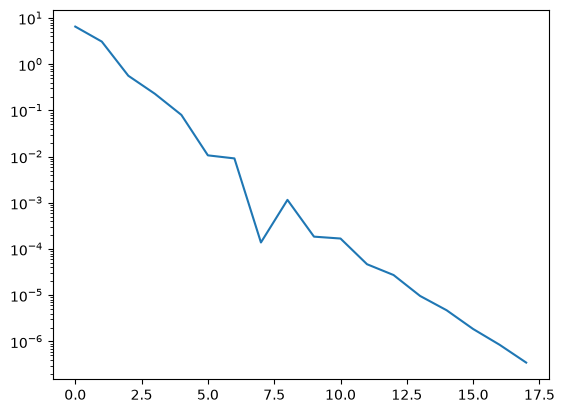

In [26]:
plt.semilogy(np.abs(error)) 

# Inverse Power iteration

What if we are interested in the smaller eigenvalue in magnitude?

Suppose ${\bf x},\lambda$ is an eigenpair of ${\bf A}$, such that ${\bf A}{\bf x}  = \lambda {\bf x}$. What would be an eigenvalue of  ${\bf A}^{-1}$?


$${\bf A}^{-1}{\bf A}{\bf x}  = {\bf A}^{-1}\lambda {\bf x}$$

$${\bf I}{\bf x}  =  \lambda {\bf A}^{-1} {\bf x}$$

$$\frac{1}{\lambda}{\bf x}  =  {\bf A}^{-1} {\bf x}$$


** Hence $\frac{1}{\lambda}$ is an eigenvalue of ${\bf A}^{-1} $ **.

If we want to find the smallest eigenvalue in magnitude of ${\bf A}$, we can perform power iteration using the matrix ${\bf A}^{-1}$ to find $\bar\lambda = \frac{1}{\lambda}$, where  $\bar\lambda$ is the largest eigenvalue of ${\bf A}^{-1}$.

Let's implement that:

In [27]:
n = 4
D = np.diag([5,-1,2,7])

A = U@D@U.T
eigl, eigv = la.eig(A)

eig_index_sort = np.argsort(abs(eigl))
eig_index_sort
eigpos = eig_index_sort[0]

print(eigv[:,eigpos])

[-0.19557136+0.j  0.96573545+0.j -0.14274286+0.j -0.09344173+0.j]


In [28]:
x0 = np.random.random(n)
nrm = la.norm(x0)
x = x0/nrm

for i in range(20):
    x = la.inv(A)@x
    x = x/la.norm(x)

print("lambdan = ",x.T@A@x/(x.T@x))
print("un = ", x) 

lambdan =  -0.9999999999994285
un =  [ 0.19557162 -0.9657354   0.14274302  0.09344143]


Can you find ways to improve the code snippet above? 

In [29]:
#Inverse Power iteration to get smallest eigenvalue
x0 = np.random.random(n)
nrm = la.norm(x0)
x = x0/nrm
P, L, Um = sla.lu(A)
for k in range(20):
    y = sla.solve_triangular(L, np.dot(P.T, x), lower=True)
    x = sla.solve_triangular(Um, y)
    x = x/la.norm(x)

print("lambdan = ",x.T@A@x/(x.T@x))
print("un = ", x)  

lambdan =  -0.9999999999846493
un =  [-0.19556997  0.9657357  -0.14274204 -0.0934433 ]


# Inverse Shifted Power Iteration

What if we want to find another eigenvalue that is not the largest or the smallest? 

Suppose ${\bf x},\lambda$ is an eigenpair of ${\bf A}$, such that ${\bf A}{\bf x}  = \lambda {\bf x}$. We want to find the eigenvalues of the shifted inverse matrix $({\bf A} - \sigma{\bf I})^{-1}$


$$({\bf A} - \sigma{\bf I})^{-1}{\bf x}  = \bar\lambda {\bf x}$$

$${\bf I}{\bf x}  =  \bar\lambda ({\bf A} - \sigma{\bf I}) {\bf x} = \bar\lambda ({\lambda \bf I} - \sigma{\bf I}) {\bf x}$$

$$  \bar\lambda  = \frac{1}{\lambda-\sigma}$$


We could write the above eigenvalue problem as 


$$ {\bf B}^{-1}{\bf x}  = \bar\lambda {\bf x}$$

which can be solved by inverse power iteration, which will converge to the eigenvalue $\frac{1}{\lambda-\sigma}$

In [30]:
n = 4
D = np.diag([5,-7,2,10])

A = U@D@U.T
eigl, eigv = la.eig(A)

print(eigl)
eigv

[-7.+0.j 10.+0.j  2.+0.j  5.+0.j]


array([[-0.19557136+0.j,  0.71339916+0.j, -0.61161878+0.j,
         0.28059926+0.j],
       [ 0.96573545+0.j,  0.08361625+0.j, -0.11062838+0.j,
         0.21937348+0.j],
       [-0.14274286+0.j, -0.61929012+0.j, -0.36443074+0.j,
         0.68065738+0.j],
       [-0.09344173+0.j,  0.31709574+0.j,  0.69345084+0.j,
         0.64019128+0.j]])

In [31]:
#Shifted Inverse Power iteration 
sigma = 1

x0 = np.random.random(n)
nrm = la.norm(x0)
x = x0/nrm
B = A - sigma*np.eye(n)
P, L, Um = sla.lu(B)
for k in range(20):
    y = sla.solve_triangular(L, np.dot(P.T, x), lower=True)
    x = sla.solve_triangular(Um, y)
    x = x/la.norm(x)

print("lambdan = ",x.T@A@x/(x.T@x))
print("un = ", x)  

lambdan =  1.9999999999999996
un =  [ 0.61161878  0.11062838  0.36443074 -0.69345084]


# Computational cost and convergence

- power iteration: to obtain largest eigenvalue in magnitude ${\lambda_1}$
    - Matrix-vector multiplications at each iteration: $O(n^2)$
    - convergence rate: $\left|\frac{\lambda_2}{\lambda_1} \right|$
    
   
- inverse power iteration: to obtain smallest eigenvalue in magnitude ${\lambda_n}$
    - only one factorization: $O(n^3)$
    - backward-forward substitutions to solve at each iteration: $O(n^2)$
    - convergence rate: $\left|\frac{\lambda_n}{\lambda_{n-1}} \right|$  
    
   
- inverse shifted power iteration: to obtain an eigenvalue close to a known/given value $\sigma$
    - only one factorization: $O(n^3)$
    - backward-forward substitutions to solve at each iteration: $O(n^2)$
    - convergence rate: $\left|\frac{\lambda_c - \sigma}{\lambda_{c2} - \sigma} \right|$  
    where $\lambda_c$ is the closest eigenvalue to $\sigma$ and $\lambda_{c2}$ is the second closest eigenvalue to $\sigma$.
   